<a href="https://colab.research.google.com/github/luisalberto49703-commits/Codes-for-Luis_Santos_paper_2/blob/main/JFNK_%2B_GMRES_without_prec.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Enter the length of the rod [m] L = 0.01
Enter the number of elements N = 10
Enter the linear heat generation [W/m] q = 1000
Enter the final simulation time [s] t_final = 2
Enter the time step [s] dt = 0.1
Temperature at left boundary [°C] T_left = 100
Temperature at right boundary [°C] T_right = 100
Initial temperature [°C] T_init = 25


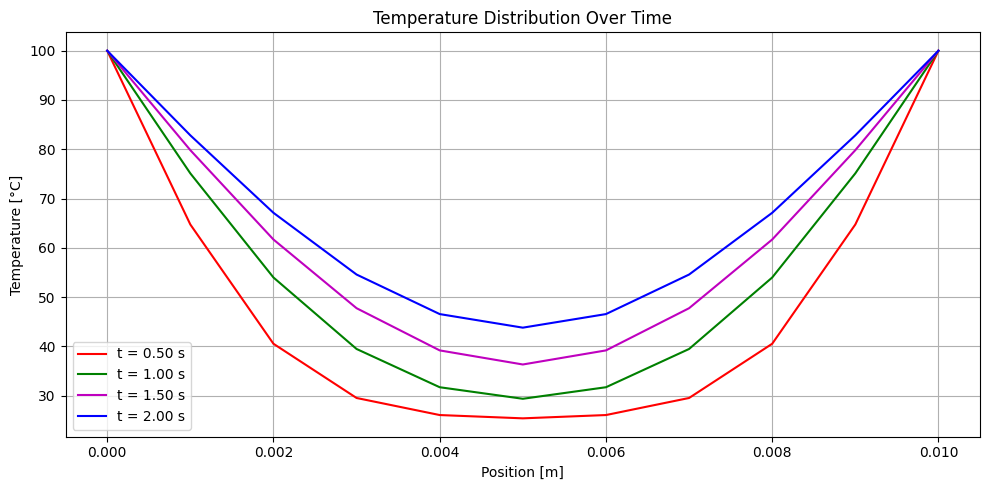

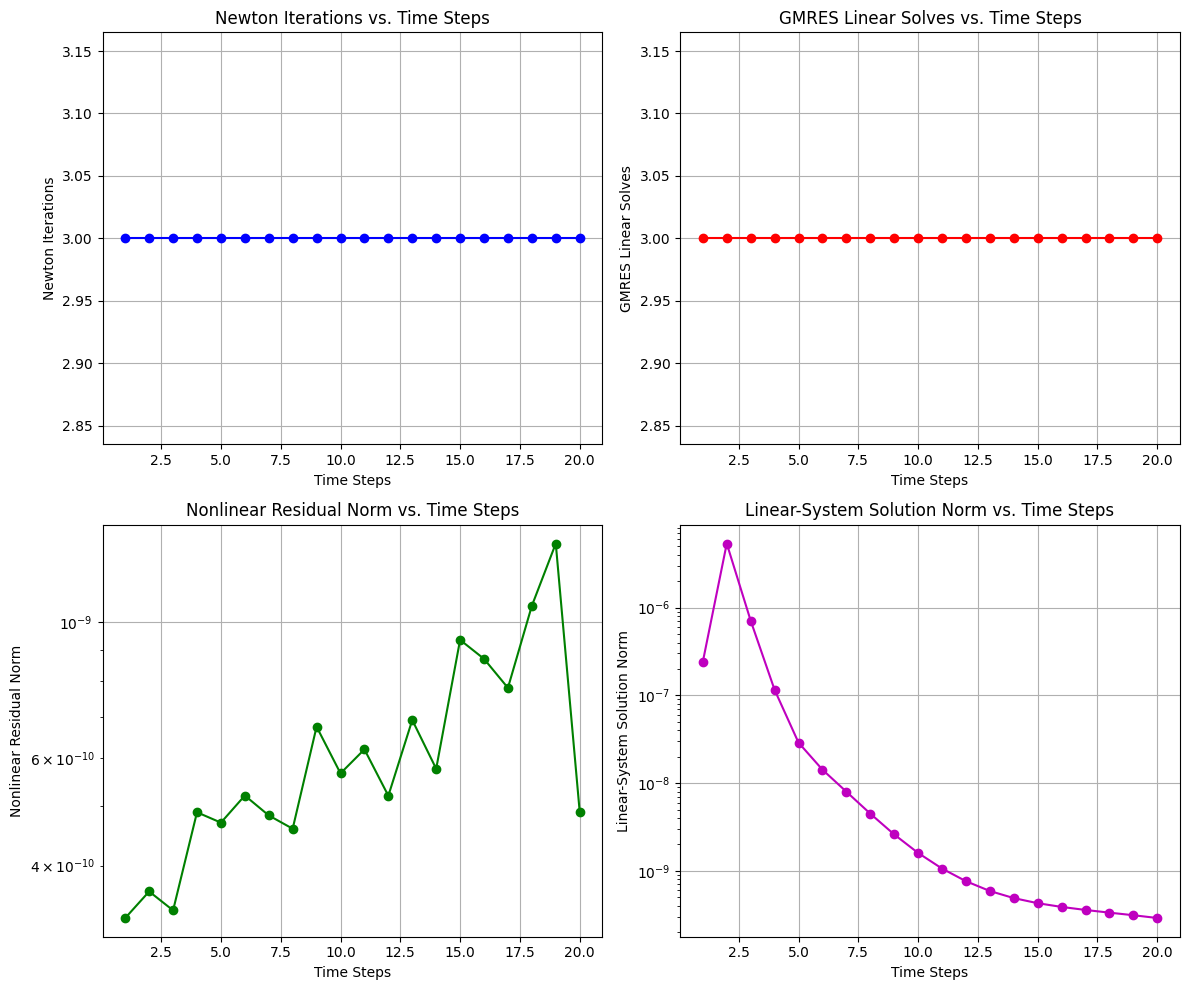


--- Performance Summary ---
Total Newton Iterations: 60
Total Execution Time: 1.694 seconds
Average Newton Iterations per Time Step: 3.00
Final Residual Norm (Nonlinear): 4.90e-10
Final Linear-System (GMRES) Solution Norm: 2.90e-10
Final Temperature Change Norm: 3.46e+00
Memory Usage: 0.00 MB
Approximate Linear-System Solves: 60
Stability Check (max T): 100.00 °C
Robustness: OK

--- Final Temperature Change Norm Study ---
t_final =    2.0 s  -->  Final Temperature Change Norm = 3.46e+00
t_final =   20.0 s  -->  Final Temperature Change Norm = 2.44e-02
t_final =   40.0 s  -->  Final Temperature Change Norm = 9.52e-05
t_final =   50.0 s  -->  Final Temperature Change Norm = 5.94e-06
t_final =   75.0 s  -->  Final Temperature Change Norm = 5.78e-09
t_final =  100.0 s  -->  Final Temperature Change Norm = 5.62e-12


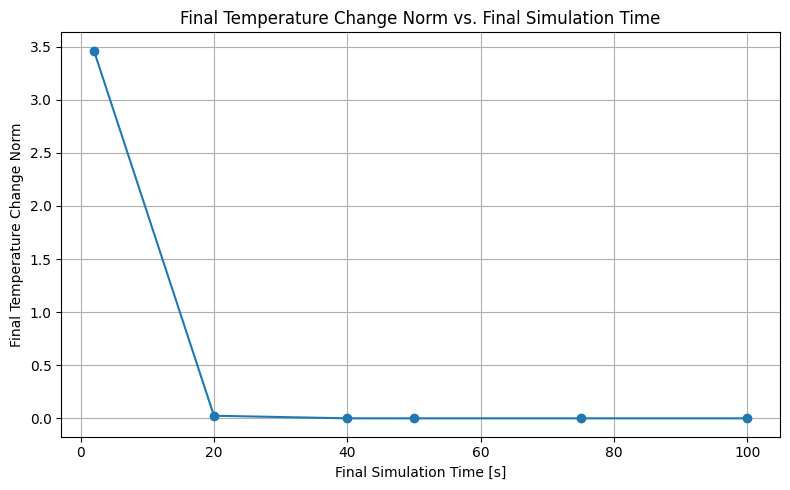



MESH REFINEMENT CONVERGENCE STUDY
Testing N =   10 ... CONVERGED
Testing N =   11 ... CONVERGED
Testing N =   12 ... CONVERGED
Testing N =   13 ... CONVERGED
Testing N =   14 ... CONVERGED
Testing N =   15 ... CONVERGED
Testing N =   16 ... CONVERGED
Testing N =   17 ... CONVERGED
Testing N =   18 ... CONVERGED
Testing N =   19 ... CONVERGED
Testing N =   20 ... CONVERGED
Testing N =   21 ... CONVERGED
Testing N =   22 ... CONVERGED
Testing N =   23 ... CONVERGED
Testing N =   24 ... CONVERGED
Testing N =   25 ... CONVERGED
Testing N =   26 ... CONVERGED
Testing N =   27 ... CONVERGED
Testing N =   28 ... CONVERGED
Testing N =   29 ... CONVERGED
Testing N =   30 ... CONVERGED
Testing N =   31 ... CONVERGED
Testing N =   32 ... CONVERGED
Testing N =   33 ... CONVERGED
Testing N =   34 ... CONVERGED
Testing N =   35 ... CONVERGED
Testing N =   36 ... CONVERGED
Testing N =   37 ... CONVERGED
Testing N =   38 ... CONVERGED
Testing N =   39 ... CONVERGED
Testing N =   40 ... CONVERGED
Tes

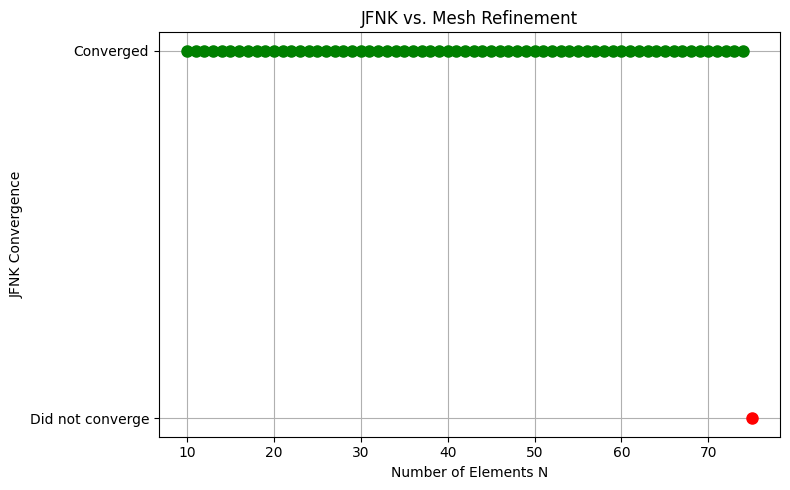


--- CSV Data Export ---
1. newton_gmres_convergence_data.csv
2. temperature_distribution_data.csv
3. final_temperature_change_norm_data.csv
4. mesh_refinement_convergence_data.csv


In [ ]:
# Author: Luís Santos - 2026

# UAB - LISBON

# Nonlinear FEM for 1D heat conduction

# Implicit Euler method with JFNK

# -------------------------------


import numpy as np

import matplotlib.pyplot as plt

import time

import psutil

import os

import tracemalloc

from scipy.sparse.linalg import LinearOperator, gmres



# =========================================================

# 1. USER INPUT

# =========================================================


L = float(input("Enter the length of the rod [m] L = "))


N = int(input("Enter the number of elements N = "))


q = float(input("Enter the linear heat generation [W/m] q = "))


t_final = float(input("Enter the final simulation time [s] t_final = "))


dt_input = float(input("Enter the time step [s] dt = "))


dt = min(dt_input, 0.1)


T_left = float(input("Temperature at left boundary [°C] T_left = "))


T_right = float(input("Temperature at right boundary [°C] T_right = "))


T_init = float(input("Initial temperature [°C] T_init = "))



# =========================================================

# 2. MATERIAL PARAMETERS

# =========================================================


alpha = 9.248

beta = 1.571e-2

gamma = 458.98

delta = 13.28e-2

eta = 8084.2

zeta = -0.42086

xi = -3.8942e-5


# =========================================================

# 3. MESH AND INITIALIZATION

# =========================================================



h = L / N

x = np.linspace(0, L, N + 1)

T = np.ones(N + 1) * T_init

nsteps = int(t_final / dt)


# =========================================================

# Global heat generation vector

# =========================================================




f_vec = np.ones(N + 1)


f_vec[1:N] = 2


f_vec = (q * h / 2.0) * f_vec


# =========================================================


# 4. FEM ASSEMBLY FUNCTIONS

# =========================================================

# ---------------------------------------------------------


# Mass matrix diagonal coefficient M_jj

# ---------------------------------------------------------




def M_jj(T, j):


    Tjm1 = T[j-1]


    Tj   = T[j]


    Tjp1 = T[j+1]


    term1 = (eta * gamma) / 3


    term2 = (


        0.25


        * (eta * delta + zeta * gamma)


        * (Tjm1 + Tj)


    )


    term3 = (


        0.2


        * (zeta * delta + xi * gamma)


        * (


            Tjm1**2


            + Tj**2


            + Tjm1 * Tj


        )



    )


    term4 = (


        (1/6)


        * xi * delta


        * (


            Tjm1**3


            + Tj**3


            + Tjm1**2 * Tj


            + Tjm1 * Tj**2


        )


    )


    term5 = (eta * gamma) / 3


    term6 = (


        0.25


        * (eta * delta + zeta * gamma)


        * (Tj + Tjp1)


    )


    term7 = (


        0.2


        * (zeta * delta + xi * gamma)


        * (


            Tj**2


            + Tjp1**2


            + Tj * Tjp1


        )


    )


    term8 = (


        (1/6)


        * xi * delta


        * (


            Tj**3


            + Tjp1**3


            + Tj**2 * Tjp1


            + Tj * Tjp1**2


        )




    )




    return h * (


        term1


        + term2


        + term3


        + term4

        + term5


        + term6


        + term7


        + term8


    )



# ---------------------------------------------------------

# Mass matrix upper off-diagonal coefficient M_j,j+1

# ---------------------------------------------------------


def M_jjp1(T, j):


    Tj = T[j]

    Tjp1 = T[j+1]


    dT = Tjp1 - Tj


    term1 = (eta * gamma) / 6


    term2 = (


        (1/6)


        * (eta * delta + zeta * gamma)


        * Tj


    )


    term3 = (


        (1/12)


        * (eta * delta + zeta * gamma)


        * dT


    )


    term4 = (



        (1/6)




        * (zeta * delta + xi * gamma)




        * Tj**2




    )


    term5 = (


        (1/6)


        * (zeta * delta + xi * gamma)


        * Tj * dT


    )


    term6 = (


        (1/20)


        * (zeta * delta + xi * gamma)


        * dT**2


    )


    term7 = (


        (1/6)


        * xi * delta

        * Tj**3


    )


    term8 = (




        (1/4)




        * xi * delta




        * Tj**2 * dT




    )






    term9 = (




        (3/20)




        * xi * delta




        * Tj * dT**2




    )






    term10 = (




        (1/30)




        * xi * delta




        * dT**3




    )






    return h * (




        term1




        + term2




        + term3




        + term4




        + term5




        + term6




        + term7




        + term8




        + term9




        + term10




    )



# ---------------------------------------------------------

# Mass matrix lower off-diagonal coefficient M_j,j-1

# ---------------------------------------------------------


def M_jmj(T, j):


    Tjm1 = T[j-1]


    Tj = T[j]


    dT = Tj - Tjm1


    term1 = (eta * gamma) / 6


    term2 = (


        (1/6)


        * (eta * delta + zeta * gamma)




        * Tjm1




    )


    term3 = (




        (1/12)




        * (eta * delta + zeta * gamma)




        * dT




    )


    term4 = (




        (1/6)




        * (zeta * delta + xi * gamma)




        * Tjm1**2




    )


    term5 = (




        (1/6)




        * (zeta * delta + xi * gamma)




        * Tjm1 * dT




    )


    term6 = (




        (1/20)




        * (zeta * delta + xi * gamma)




        * dT**2




    )


    term7 = (




        (1/6)




        * xi * delta




        * Tjm1**3




    )



    term8 = (




        (1/4)




        * xi * delta




        * Tjm1**2 * dT




    )


    term9 = (




        (3/20)




        * xi * delta




        * Tjm1 * dT**2




    )



    term10 = (




        (1/30)




        * xi * delta




        * dT**3




    )



    return h * (




        term1




        + term2




        + term3




        + term4




        + term5




        + term6




        + term7




        + term8




        + term9




        + term10




    )



# =========================================================

# Derivatives of mass matrix terms

# =========================================================

# ---------------------------------------------------------

# dM_j,j-1 / dT_j-1

# ---------------------------------------------------------

def dMjm1j_dTjm1(T, j):


    Tjm1 = T[j-1]


    Tj = T[j]


    return h * (


        (1/12) * (eta * delta + zeta * gamma)


        + (1/10)


        * (zeta * delta + xi * gamma)


        * Tjm1


        + (1/15)


        * (zeta * delta + xi * gamma)

        * Tj


        + (1/10)


        * xi * delta


        * Tjm1**2


        + (1/10)


        * xi * delta


        * Tjm1 * Tj


        + (1/20)


        * xi * delta


        * Tj**2



    )




# ---------------------------------------------------------

# dM_j,j-1 / dT_j

# ---------------------------------------------------------


def dMjm1j_dTj(T, j):


    Tjm1 = T[j-1]

    Tj = T[j]

    return h * (


        (1/12) * (eta * delta + zeta * gamma)


        + (1/15)


        * (zeta * delta + xi * gamma)


        * Tjm1


        + (1/10)


        * (zeta * delta + xi * gamma)


        * Tj


        + (1/20)


        * xi * delta


        * Tjm1**2


        + (1/10)


        * xi * delta


        * Tjm1 * Tj


        + (1/10)


        * xi * delta


        * Tj**2


    )



# ---------------------------------------------------------

# dM_jj / dT_j-1

# ---------------------------------------------------------



def dMjj_dTjm1(T, j):


    Tjm1 = T[j-1]


    Tj = T[j]


    Tjp1 = T[j+1]


    return h * (


        (1/4) * (eta * delta + zeta * gamma)



        + (1/5)


        * (zeta * delta + xi * gamma)


        * (2 * Tjm1 + Tj)


        + (1/6)


        * xi * delta


        * (


            3 * Tjm1**2


            + 2 * Tjm1 * Tj


            + Tj**2


        ))


# ---------------------------------------------------------

# dM_jj / dT_j

# ---------------------------------------------------------

def dMjj_dTj(T, j):


    Tjm1 = T[j-1]

    Tj = T[j]

    Tjp1 = T[j+1]


    return h * (


        (1/2) * (eta * delta + zeta * gamma)


        + (zeta * delta + xi * gamma)


        * (


            (4/5) * Tj




            + (1/5) * Tjm1




            + (1/5) * Tjp1




        )








        + xi * delta




        * (




            Tj**2




            + (1/3) * Tj * Tjm1




            + (1/3) * Tj * Tjp1




            + (1/6) * Tjm1**2




            + (1/6) * Tjp1**2




        )




    )


# ---------------------------------------------------------

# dM_jj / dT_j+1

# ---------------------------------------------------------


def dMjj_dTjp1(T, j):


    Tj = T[j]




    Tjp1 = T[j+1]








    return h * (




        (1/4) * (eta * delta + zeta * gamma)








        + (1/5)




        * (zeta * delta + xi * gamma)




        * Tj








        + (2/5)




        * (zeta * delta + xi * gamma)




        * Tjp1








        + (1/6)




        * xi * delta




        * Tj**2








        + (1/3)




        * xi * delta




        * Tj * Tjp1








        + (1/2)




        * xi * delta




        * Tjp1**2




    )






# ---------------------------------------------------------




# dM_j,j+1 / dT_j




# ---------------------------------------------------------








def dMjjp1_dTj(T, j):








    Tj = T[j]




    Tjp1 = T[j+1]








    return h * (


        (1/12) * (eta * delta + zeta * gamma)


        + (1/15)




        * (zeta * delta + xi * gamma)




        * Tj


        + (1/10)


        * (zeta * delta + xi * gamma)




        * Tjp1


        + (1/20)




        * xi * delta




        * Tj**2


        + (1/10)




        * xi * delta




        * Tj * Tjp1

        + (1/10)




        * xi * delta




        * Tjp1**2




    )




# ---------------------------------------------------------
# dM_j,j+1 / dT_j+1

# ---------------------------------------------------------


def dMjjp1_dTjp1(T, j):


    Tj = T[j]

    Tjp1 = T[j+1]

    return h * (



        (1/12) * (eta * delta + zeta * gamma)


        + (1/10)


        * (zeta * delta + xi * gamma)


        * Tj


        + (1/15)


        * (zeta * delta + xi * gamma)

        * Tjp1

        + (1/10)


        * xi * delta




        * Tj**2



        + (1/10)




        * xi * delta




        * Tj * Tjp1


        + (1/20)




        * xi * delta




        * Tjp1**2




    )




# =========================================================
# Stiffness matrix terms
# =========================================================

def K_jj(T, j):


    return (1 / h) * (


        2 * alpha


        + 0.5 * beta


        * (



            T[j-1]

            + 2 * T[j]

            + T[j+1]

        )


    )


def K_jjm1(T, j):

    return -(1 / h) * (


        alpha


        + 0.5 * beta


        * (

            T[j-1]


            + T[j]


        ))


def K_jjp1(T, j):

    return -(1 / h) * (

        alpha

        + 0.5 * beta

        * (


            T[j]


            + T[j+1]


        ))

# =========================================================
# Boundary/source contribution
# =========================================================

def compute_B(T, j):

    B = np.zeros(N + 1)

    B[j-1] = (

        T[j] / h




        * (




            alpha




            + beta * T[j-1]




        )




    )



    B[j+1] = -(


        T[j] / h


        * (

            alpha

            + beta * T[j+1]


        ) )

    return B


# =========================================================
# 5. RESIDUAL FUNCTION
# =========================================================


def residual(T_new, T_old):

    F = np.zeros(N + 1)


    for j in range(1, N):








        # Mass matrix coefficients




        Mjj = M_jj(T_new, j)




        Mjmj = M_jmj(T_new, j)




        Mjjp1 = M_jjp1(T_new, j)








        # Stiffness coefficients




        Kj = K_jj(T_new, j)




        Kjm1 = K_jjm1(T_new, j)




        Kjp1 = K_jjp1(T_new, j)








        # Boundary contribution




        B_term = compute_B(T_new, j)








        # Transient contribution




        M_term = (




            Mjmj




            * (T_new[j-1] - T_old[j-1])








            + Mjj




            * (T_new[j] - T_old[j])








            + Mjjp1




            * (T_new[j+1] - T_old[j+1])




        ) / dt








        # Conductive contribution




        f_term = (




            Kj * T_new[j]




            + Kjm1 * T_new[j-1]




            + Kjp1 * T_new[j+1]




        )








        # Nonlinear residual




        F[j] = (




            M_term




            + f_term




            - B_term[j]




            - f_vec[j]




        )








    # Dirichlet boundary conditions




    F[0] = 0.0




    F[-1] = 0.0








    return F




# =========================================================




# =========================================================

# 6. JFNK / GMRES PARAMETERS AND MATRIX-FREE JACOBIAN

# =========================================================


newton_tol = 1e-8

max_newton_iterations = 50


# Finite-difference parameter for matrix-free J*v

eps_fd = 1e-7


# GMRES parameters

# No preconditioner is used.

gmres_tol = 1e-6

gmres_restart = 100

gmres_maxiter = 1000



def jv_product(v, T_current, T_old, F_base):

    """

    Matrix-free approximation of J(T) @ v:


        J(T)v ~= [F(T + eps*v) - F(T)] / eps


    The Jacobian matrix is never assembled and no preconditioner

    is used. Dirichlet boundary nodes are kept fixed.

    """


    v_norm = np.linalg.norm(v)


    if v_norm == 0.0:

        return np.zeros_like(v)


    T_norm = np.linalg.norm(T_current[1:N])

    T_scale = max(1.0, T_norm)

    eps = eps_fd * T_scale / v_norm


    T_perturbed = T_current.copy()

    T_perturbed[1:N] += eps * v


    T_perturbed[0] = T_left

    T_perturbed[-1] = T_right


    F_perturbed = residual(T_perturbed, T_old)


    return (

        F_perturbed[1:N] - F_base[1:N]

    ) / eps



def build_jfnk_operator(T_current, T_old, F_base):


    n_unknowns = N - 1


    def matvec(v):

        return jv_product(

            v,

            T_current,

            T_old,

            F_base

        )


    return LinearOperator(

        shape=(n_unknowns, n_unknowns),

        matvec=matvec,

        dtype=float

    )


# 7. PERFORMANCE TRACKING




# =========================================================








total_iterations = 0








residual_norms_nonlinear = []




linear_solution_norms = []




error_norms = []








nonlinear_iterations_per_timestep = []




linear_solves_per_timestep = []








# Memory measurement




initial_memory = psutil.Process(




    os.getpid()




).memory_info().rss
tracemalloc.start()
t_start = time.time()


# =========================================================
# =========================================================
# 7.1. PARAMETRIC STUDY: FINAL TEMPERATURE CHANGE NORM
# =========================================================

def run_temperature_change_simulation(t_final_test):

    nsteps_test = int(t_final_test / dt)

    T_test = np.ones(N + 1) * T_init


    # Keep the initial state identical to the main simulation.

    # The Dirichlet boundary conditions are imposed only after

    # T_old_test has been copied at the beginning of each time step.

    error_norms_test = []


    for step in range(1, nsteps_test + 1):


        T_old_test = T_test.copy()

        converged = False


        for k in range(max_newton_iterations):


            T_test[0] = T_left

            T_test[-1] = T_right


            F_test = residual(T_test, T_old_test)

            F_norm = np.linalg.norm(F_test[1:N])


            if F_norm < newton_tol:

                converged = True

                break


            J_operator = build_jfnk_operator(

                T_test,

                T_old_test,

                F_test

            )


            gmres_residuals_test = []


            def gmres_callback_test(value):

                gmres_residuals_test.append(float(value))


            dT_test, gmres_info = gmres(

                J_operator,

                -F_test[1:N],

                rtol=gmres_tol,

                atol=0.0,

                restart=gmres_restart,

                maxiter=gmres_maxiter,

                callback=gmres_callback_test,

                callback_type='pr_norm'

            )


            if gmres_info != 0:

                raise RuntimeError(

                    f"JFNK/GMRES did not converge at "

                    f"t = {step * dt:.6e} s for "

                    f"t_final = {t_final_test} s. "

                    f"GMRES info = {gmres_info}"

                )


            T_test[1:N] += dT_test

            T_test[0] = T_left

            T_test[-1] = T_right


            F_new_test = residual(T_test, T_old_test)

            res_norm_test = np.linalg.norm(F_new_test[1:N])


            if res_norm_test < newton_tol:

                converged = True

                break


        if not converged:

            raise RuntimeError(

                f"Newton/JFNK did not converge at "

                f"t = {step * dt:.6e} s for "

                f"t_final = {t_final_test} s."

            )


        error_norms_test.append(

            np.linalg.norm(T_test - T_old_test)

        )


    return error_norms_test[-1]


# =========================================================
# 8. TIME INTEGRATION LOOP
# =========================================================


T_saved = []


save_times = [

    0.25 * t_final,

    0.50 * t_final,

    0.75 * t_final,

    t_final

]


save_steps = [

    int(t / dt)

    for t in save_times

]


for step in range(1, nsteps + 1):


    T_old = T.copy()


    # -----------------------------------------------------

    # Newton iterations with matrix-free JFNK + GMRES

    # -----------------------------------------------------


    converged = False

    gmres_iterations_this_step = 0


    for k in range(max_newton_iterations):


        # Enforce Dirichlet boundary conditions

        T[0] = T_left

        T[-1] = T_right


        # Evaluate nonlinear residual

        F = residual(T, T_old)

        F_norm = np.linalg.norm(F[1:N])


        # Convergence before another linear solve

        if F_norm < newton_tol:

            converged = True

            dT = np.zeros(N - 1)

            res_norm = F_norm

            break


        # -------------------------------------------------

        # Matrix-free Jacobian operator

        # -------------------------------------------------


        J_operator = build_jfnk_operator(

            T,

            T_old,

            F

        )


        # -------------------------------------------------

        # GMRES solution of J*dT = -F

        # -------------------------------------------------


        gmres_residuals = []


        def gmres_callback(value):

            gmres_residuals.append(float(value))


        dT, gmres_info = gmres(

            J_operator,

            -F[1:N],

            rtol=gmres_tol,

            atol=0.0,

            restart=gmres_restart,

            maxiter=gmres_maxiter,

            callback=gmres_callback,

            callback_type='pr_norm'

        )


        gmres_iterations_this_step += len(gmres_residuals)


        if gmres_info != 0:

            raise RuntimeError(

                f"JFNK/GMRES did not converge at "

                f"time step {step} "

                f"(t = {step * dt:.6e} s), "

                f"Newton iteration {k + 1}. "

                f"GMRES info = {gmres_info}"

            )


        # Newton update

        T[1:N] += dT


        # Re-enforce Dirichlet boundary conditions

        T[0] = T_left

        T[-1] = T_right


        # -------------------------------------------------

        # Evaluate residual AFTER JFNK update

        # -------------------------------------------------


        F_new = residual(T, T_old)

        res_norm = np.linalg.norm(F_new[1:N])


        # -------------------------------------------------

        # Convergence criterion

        # -------------------------------------------------


        if res_norm < newton_tol:

            converged = True

            break


    # -----------------------------------------------------

    # Check JFNK convergence

    # -----------------------------------------------------


    if not converged:

        raise RuntimeError(

            f"Newton/JFNK did not converge at "

            f"time step {step} "

            f"(t = {step * dt:.6e} s). "

            f"Final residual norm = {res_norm:.6e}"

        )


    # -----------------------------------------------------

    # Performance quantities

    # -----------------------------------------------------


    total_iterations += k + 1


    residual_norms_nonlinear.append(

        res_norm

    )


    linear_solution_norms.append(

        np.linalg.norm(dT)

    )


    nonlinear_iterations_per_timestep.append(

        k + 1

    )


    # One GMRES linear solve per JFNK/Newton iteration

    linear_solves_per_timestep.append(

        k + 1

    )


    error_norms.append(

        np.linalg.norm(T - T_old)

    )


    # -----------------------------------------------------

    # Save temperature field

    # -----------------------------------------------------


    if step in save_steps:

        T_saved.append(T.copy())


# Convert saved solutions to array

T_saved = np.array(T_saved).T


# 9. MEMORY AND EXECUTION TIME


# =========================================================


total_time = time.time() - t_start


final_memory = psutil.Process(

    os.getpid()


).memory_info().rss


memory_used = (


    final_memory - initial_memory




) / (1024 ** 2)



tracemalloc.stop()



# =========================================================

# 10. TEMPERATURE DISTRIBUTION PLOT

# =========================================================


plt.figure(figsize=(10, 5))


colors = ['r', 'g', 'm', 'b']


for i in range(len(save_times)):






    plt.plot(




        x,




        T_saved[:, i],




        color=colors[i],




        label=f't = {save_times[i]:.2f} s'




    )






plt.xlabel('Position [m]')




plt.ylabel('Temperature [°C]')




plt.title('Temperature Distribution Over Time')




plt.legend()




plt.grid(True)




plt.tight_layout()




plt.show()



# =========================================================
# 11. NEWTON AND CONVERGENCE INFORMATION
# =========================================================

plt.figure(figsize=(12, 10))

# ---------------------------------------------------------
# Nonlinear iterations
# ---------------------------------------------------------


plt.subplot(2, 2, 1)

plt.plot(

    range(1, nsteps + 1),
    nonlinear_iterations_per_timestep,

    'b-o'

)


plt.xlabel('Time Steps')

plt.ylabel('Newton Iterations')
plt.title('Newton Iterations vs. Time Steps')
plt.grid(True)

# ---------------------------------------------------------

# Direct linear solves

# ---------------------------------------------------------

plt.subplot(2, 2, 2)


plt.plot(

    range(1, nsteps + 1),
    linear_solves_per_timestep,
    'r-o'

)

plt.xlabel('Time Steps')




plt.ylabel('GMRES Linear Solves')

plt.title('GMRES Linear Solves vs. Time Steps')

plt.grid(True)

# ---------------------------------------------------------

# Nonlinear residual

# ---------------------------------------------------------

plt.subplot(2, 2, 3)


plt.semilogy(


    range(1, nsteps + 1),

    residual_norms_nonlinear,

    'g-o'

)


plt.xlabel('Time Steps')




plt.ylabel('Nonlinear Residual Norm')

plt.title('Nonlinear Residual Norm vs. Time Steps')


plt.grid(True)



# ---------------------------------------------------------

# Newton correction

# ---------------------------------------------------------


plt.subplot(2, 2, 4)

plt.semilogy(

    range(1, nsteps + 1),

    linear_solution_norms,

    'm-o'

)

plt.xlabel('Time Steps')

plt.ylabel('Linear-System Solution Norm')

plt.title('Linear-System Solution Norm vs. Time Steps')

plt.grid(True)

plt.tight_layout()

plt.show()


# =========================================================

# 12. PERFORMANCE REPORT

# =========================================================


print("\n--- Performance Summary ---")

print(

    f"Total Newton Iterations: "
    f"{total_iterations}"

)

print(

    f"Total Execution Time: "

    f"{total_time:.3f} seconds"

)


print(

    f"Average Newton Iterations per Time Step: "

    f"{total_iterations / nsteps:.2f}"

)

print(

    f"Final Residual Norm (Nonlinear): "

    f"{residual_norms_nonlinear[-1]:.2e}"

)

print(

    f"Final Linear-System (GMRES) Solution Norm: "

    f"{linear_solution_norms[-1]:.2e}"

)



print(

    f"Final Temperature Change Norm: "


    f"{error_norms[-1]:.2e}"


)


print(




    f"Memory Usage: "




    f"{memory_used:.2f} MB"




)




print(




    f"Approximate Linear-System Solves: "




    f"{total_iterations}"




)




print(




    f"Stability Check (max T): "




    f"{np.max(T):.2f} °C"




)




print(




    f"Robustness: "




    f"{'OK' if np.max(T) < 1e4 else 'Check'}"




)


# =========================================================
# 13. FINAL TEMPERATURE CHANGE NORM VS. FINAL TIME
# =========================================================

t_final_values = [2, 20, 40, 50, 75,100]

final_temperature_change_norms = []

print("\n--- Final Temperature Change Norm Study ---")


for t_test in t_final_values:

    final_norm = run_temperature_change_simulation(




        t_test




    )

    final_temperature_change_norms.append(


        final_norm


    )


    print(




        f"t_final = {t_test:6.1f} s  -->  "




        f"Final Temperature Change Norm = "




        f"{final_norm:.2e}"


    )


# ---------------------------------------------------------
# Plot
# ---------------------------------------------------------


plt.figure(figsize=(8, 5))








plt.plot(




    t_final_values,




    final_temperature_change_norms,




    'o-'




)








plt.xlabel('Final Simulation Time [s]')




plt.ylabel('Final Temperature Change Norm')








plt.title(




    'Final Temperature Change Norm vs. Final Simulation Time'




)








plt.grid(True)




plt.tight_layout()




plt.show()






# =========================================================
# =========================================================

# 14. MESH REFINEMENT: FIND FIRST NON-CONVERGENT N

# =========================================================



def test_convergence_for_N(N_test):

    """

    Run the complete transient simulation for a prescribed mesh size N_test

    using the same FEM residual as the main simulation and JFNK + GMRES

    without preconditioning.

    """


    global N, h, f_vec


    N_original = N

    h_original = h

    f_vec_original = f_vec.copy()


    try:


        N = int(N_test)

        h = L / N


        f_vec = np.ones(N + 1)

        f_vec[1:N] = 2

        f_vec = (q * h / 2.0) * f_vec


        T_test = np.full(

            N + 1,

            T_init,

            dtype=float

        )

        T_test[0] = T_left

        T_test[-1] = T_right


        nsteps_test = int(t_final / dt)


        for step in range(1, nsteps_test + 1):


            T_old = T_test.copy()

            converged = False


            for k in range(max_newton_iterations):


                T_test[0] = T_left

                T_test[-1] = T_right


                F = residual(T_test, T_old)


                if not np.all(np.isfinite(F)):

                    return False


                F_norm = np.linalg.norm(F[1:N])


                if F_norm < newton_tol:

                    converged = True

                    break


                J_operator = build_jfnk_operator(

                    T_test,

                    T_old,

                    F

                )


                try:

                    dT, gmres_info = gmres(

                        J_operator,

                        -F[1:N],

                        rtol=gmres_tol,

                        atol=0.0,

                        restart=gmres_restart,

                        maxiter=gmres_maxiter

                    )

                except Exception:

                    return False


                if gmres_info != 0:

                    return False


                if not np.all(np.isfinite(dT)):

                    return False


                T_test[1:N] += dT

                T_test[0] = T_left

                T_test[-1] = T_right


                F_new = residual(T_test, T_old)


                if not np.all(np.isfinite(F_new)):

                    return False


                res_norm = np.linalg.norm(F_new[1:N])


                if res_norm < newton_tol:

                    converged = True

                    break


            if not converged:

                return False


        return True


    finally:

        N = N_original

        h = h_original

        f_vec = f_vec_original


# 14.1. PARAMETERS OF THE MESH STUDY


# =========================================================


print("\n")


print("=" * 70)


print("MESH REFINEMENT CONVERGENCE STUDY")


print("=" * 70)



# First mesh to test


N_start = 10


# Increase N by this amount at every test


N_increment = 1



# Safety limit: the search stops here if every tested mesh converges


N_max = 1000



# Store results


N_tested = []


convergence_results = []




first_non_convergent_N = None


last_convergent_N = None



# =========================================================

# 14.2. TEST SUCCESSIVELY REFINED MESHES

# =========================================================



for N_test in range(


    N_start,


    N_max + 1,


    N_increment


):


    print(


        f"Testing N = {N_test:4d} ... ",


        end="",


        flush=True


    )


    converged = test_convergence_for_N(


        N_test


    )


    N_tested.append(N_test)


    convergence_results.append(converged)


    if converged:


        last_convergent_N = N_test


        print("CONVERGED")


    else:


        first_non_convergent_N = N_test


        print("DID NOT CONVERGE")


        # Stop at the first non-convergent mesh


        break


# =========================================================

# 14.3. REPORT

# =========================================================




print("\n" + "=" * 70)


print("MESH REFINEMENT RESULT")


print("=" * 70)


if first_non_convergent_N is not None:


    print(


        f"First non-convergent mesh: N = "


        f"{first_non_convergent_N}"


    )


    print(


        f"Corresponding element size: h = "


        f"{L / first_non_convergent_N:.6e} m"


    )


    if last_convergent_N is not None:




        print(


            f"Last convergent mesh: N = "


            f"{last_convergent_N}"


        )


        print(


            f"Corresponding element size: h = "


            f"{L / last_convergent_N:.6e} m"


        )


else:


    print(


        f"All tested meshes converged up to N = {N_max}."


    )

print("=" * 70)


# =========================================================

# 14.4. PLOT CONVERGENCE / NON-CONVERGENCE

# =========================================================


plt.figure(figsize=(8, 5))


for i in range(len(N_tested)):


    if convergence_results[i]:


        plt.plot(


            N_tested[i],


            1,


            'go',


            markersize=8


        )


    else:


        plt.plot(


            N_tested[i],


            0,


            'ro',


            markersize=8


        )


plt.xlabel('Number of Elements N')


plt.ylabel('JFNK Convergence')


plt.yticks(


    [0, 1],


    ['Did not converge', 'Converged']


)


plt.title(


    'JFNK vs. Mesh Refinement'


)


plt.grid(True)


plt.tight_layout()


plt.show()

# =========================================================
# EXPORT GRAPH DATA TO CSV
# =========================================================

import csv

# ---------------------------------------------------------
# 1. Newton / GMRES convergence data
# ---------------------------------------------------------
with open("newton_gmres_convergence_data.csv", "w",
          newline="", encoding="utf-8") as file:

    writer = csv.writer(file)

    writer.writerow([
        "Time Step",
        "Newton Iterations",
        "GMRES Linear Solves",
        "Nonlinear Residual Norm",
        "Linear-System Solution Norm",
        "Temperature Change Norm"
    ])

    for i in range(len(nonlinear_iterations_per_timestep)):
        writer.writerow([
            i + 1,
            nonlinear_iterations_per_timestep[i],
            linear_solves_per_timestep[i],
            residual_norms_nonlinear[i],
            linear_solution_norms[i],
            error_norms[i]
        ])


# ---------------------------------------------------------
# 2. Temperature distribution data
# ---------------------------------------------------------
with open("temperature_distribution_data.csv", "w",
          newline="", encoding="utf-8") as file:

    writer = csv.writer(file)

    writer.writerow([
        "Position [m]",
        "T at 25% final time [degC]",
        "T at 50% final time [degC]",
        "T at 75% final time [degC]",
        "T at 100% final time [degC]"
    ])

    for i in range(len(x)):
        writer.writerow([
            x[i],
            T_saved[i, 0],
            T_saved[i, 1],
            T_saved[i, 2],
            T_saved[i, 3]
        ])


# ---------------------------------------------------------
# 3. Final temperature change norm data
# ---------------------------------------------------------
with open("final_temperature_change_norm_data.csv", "w",
          newline="", encoding="utf-8") as file:

    writer = csv.writer(file)

    writer.writerow([
        "Final Simulation Time [s]",
        "Final Temperature Change Norm"
    ])

    for i in range(len(t_final_values)):
        writer.writerow([
            t_final_values[i],
            final_temperature_change_norms[i]
        ])


# ---------------------------------------------------------
# 4. Mesh refinement convergence data
# ---------------------------------------------------------
with open("mesh_refinement_convergence_data.csv", "w",
          newline="", encoding="utf-8") as file:

    writer = csv.writer(file)

    writer.writerow([
        "Number of Elements N",
        "Element Size h [m]",
        "JFNK Convergence"
    ])

    for i in range(len(N_tested)):
        writer.writerow([
            N_tested[i],
            L / N_tested[i],
            "Converged" if convergence_results[i]
            else "Did not converge"
        ])


print("\n--- CSV Data Export ---")
print("1. newton_gmres_convergence_data.csv")
print("2. temperature_distribution_data.csv")
print("3. final_temperature_change_norm_data.csv")
print("4. mesh_refinement_convergence_data.csv")